## Why XGBoost should work well

XGBoost is a boosting-based ensemble method that builds trees sequentially, where each new tree focuses on correcting the errors of the previous ones. Unlike Random Forest, which averages many independent trees, XGBoost gradually improves difficult predictions.

We expect XGBoost to perform well on this credit default dataset because:

- the relationship between predictors and default risk is likely non-linear
- strong interaction effects may exist between variables such as late payments, utilization, income, and debt ratio
- the dataset is tabular and mostly numerical, which is a setting where boosted trees often perform very well
- XGBoost includes regularization, shrinkage, and tree constraints, which help control overfitting while maintaining strong predictive power

Based on the EDA and previous models, features such as `total_late_payments`, `credit_line_utilization`, and debt-related variables appear highly informative. XGBoost is well suited to exploit such patterns.

In [3]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, roc_curve
)

from xgboost import XGBClassifier

In [4]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

train.head()

Train shape: (72161, 12)
Test shape: (48108, 11)


,Id,age,number_dependent_family_members,monthly_income,number_of_credit_lines,real_estate_loans,ratio_debt_payment_to_income,credit_line_utilization,number_of_previous_late_payments_up_to_59_days,number_of_previous_late_payments_up_to_89_days,number_of_previous_late_payments_90_days_or_more,defaulted_on_loan
0,1,66.0,NaN,4000.0,NaN,1.0,0.569108,0.05488766900000001,0.0,0.0,0.0,0
1,2,61.0,2.0,4000.0,6.0,1.0,0.297176,0.10194991099999999,0.0,0.0,0.0,0
2,3,31.0,2.0,3040.0,8.0,0.0,0.160145,1.22713507,4.0,0.0,0.0,1
3,4,54.0,4.0,10218.0,5.0,0.0,0.067913,0.08327777900000001,0.0,0.0,0.0,0
4,5,29.0,0.0,4468.0,6.0,0.0,0.328261,0.317445504,0.0,0.0,0.0,0


In [5]:
def convert_comma_decimal(df):
    df = df.copy()

    for col in df.columns:
        if df[col].dtype == "object":
            df[col] = df[col].astype(str).str.strip()
            df[col] = df[col].str.replace(",", ".", regex=False)
            df[col] = pd.to_numeric(df[col], errors="coerce")

    return df

train = convert_comma_decimal(train)
test = convert_comma_decimal(test)

In [6]:
print(train.dtypes)
print()
print(test.dtypes)

Id                                                    int64
age                                                 float64
number_dependent_family_members                     float64
monthly_income                                      float64
number_of_credit_lines                              float64
real_estate_loans                                   float64
ratio_debt_payment_to_income                        float64
credit_line_utilization                             float64
number_of_previous_late_payments_up_to_59_days      float64
number_of_previous_late_payments_up_to_89_days      float64
number_of_previous_late_payments_90_days_or_more    float64
defaulted_on_loan                                     int64
dtype: object

Id                                                    int64
age                                                 float64
number_dependent_family_members                     float64
monthly_income                                      float64
number_of_credit_lines   

In [7]:
train["total_late_payments"] = (
    train["number_of_previous_late_payments_up_to_59_days"] +
    train["number_of_previous_late_payments_up_to_89_days"] +
    train["number_of_previous_late_payments_90_days_or_more"]
)

test["total_late_payments"] = (
    test["number_of_previous_late_payments_up_to_59_days"] +
    test["number_of_previous_late_payments_up_to_89_days"] +
    test["number_of_previous_late_payments_90_days_or_more"]
)

train["log_income"] = np.log1p(train["monthly_income"])
test["log_income"] = np.log1p(test["monthly_income"])

train["log_debt_ratio"] = np.log1p(train["ratio_debt_payment_to_income"])
test["log_debt_ratio"] = np.log1p(test["ratio_debt_payment_to_income"])

In [8]:
TARGET = "defaulted_on_loan"
ID_COL = "Id"

features = [
    "age",
    "number_dependent_family_members",
    "number_of_credit_lines",
    "real_estate_loans",
    "credit_line_utilization",
    "total_late_payments",
    "log_income",
    "log_debt_ratio"
]

X = train[features].copy()
y = train[TARGET].copy()
test_ids = test["Id"]
test = test.drop(columns=["Id"])
X_test_final = test[features].copy()

print("Selected features:")
print(features)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget proportions:")
print(y.value_counts(normalize=True))

Selected features:
['age', 'number_dependent_family_members', 'number_of_credit_lines', 'real_estate_loans', 'credit_line_utilization', 'total_late_payments', 'log_income', 'log_debt_ratio']

Target distribution:
defaulted_on_loan
0    67148
1     5013
Name: count, dtype: int64

Target proportions:
defaulted_on_loan
0    0.93053
1    0.06947
Name: proportion, dtype: float64


In [9]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)

X_train: (57728, 8)
X_valid: (14433, 8)


In [10]:
numeric_features = X_train.columns

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features)
])

Here I tried to change how the model was trained. I used this trick before in class 
and it helped with very conservative models (again here is really a question about the goal,
same as we had with random forest - there the tuning of the threshold would also probably helped to improve

- I changed the scale_pos_weight in the following way:

The dataset is imbalanced as we saw a lot of times, we have class 0 = non-default = many examples
and class 1 = default = few examples
So during training, the model are getting very good with predicting class 0 because that already gives decent performance. Changing scale pos weight in such a way will tell model - "mistakes on class 1 are more important, please pay attention here"

Ratio = # of negatives/# of positives
Then numerically = 67148/5013 = 13.4, meaning class 1 errors get weighted roughly 13 times more strongly than class 0 errors. This helps to improve recall for class 1 and false negativs go down, prescission actually also can decrease because main amount of samples (class 0) will be getting less attention from model, but it is okay. ROC AUC may improve a bit or not, numerically I didnt see much effect in this metric.

In [37]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="auc",
    scale_pos_weight=ratio,
    random_state=42,
    n_jobs=-1
)
#Original model
#xgb = XGBClassifier(
#    objective="binary:logistic",
#    eval_metric="auc",
#    random_state=42,
#    n_jobs=-1
#)

pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", xgb)
])

In [38]:
param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.05, 0.1],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0]
}

In [39]:
grid = GridSearchCV(
    pipe,
    param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

grid.fit(X_train, y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__colsample_bytree': [0.8, 1.0], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [3, 5, ...], 'model__n_estimators': [200, 400], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation

In [40]:
print("Best CV ROC-AUC:", grid.best_score_)
print("\nBest parameters:")
print(grid.best_params_)

Best CV ROC-AUC: 0.8267945616534632

Best parameters:
{'model__colsample_bytree': 0.8, 'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200, 'model__subsample': 0.8}


In [41]:
cv_results = pd.DataFrame(grid.cv_results_)

cols = [
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "std_train_score",
    "param_model__n_estimators",
    "param_model__max_depth",
    "param_model__learning_rate",
    "param_model__subsample",
    "param_model__colsample_bytree"
]

top_models = cv_results[cols].sort_values("rank_test_score").head(10)
display(top_models)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,param_model__n_estimators,param_model__max_depth,param_model__learning_rate,param_model__subsample,param_model__colsample_bytree
0,1,0.826795,0.006096,0.843092,0.001699,200,3,0.05,0.8,0.8
24,2,0.826463,0.006264,0.843781,0.001659,200,3,0.05,0.8,1.0
25,3,0.826461,0.006349,0.842383,0.001671,200,3,0.05,1.0,1.0
2,4,0.826067,0.006375,0.855330,0.001428,400,3,0.05,0.8,0.8
1,5,0.825988,0.006779,0.842034,0.001565,200,3,0.05,1.0,0.8
26,6,0.825624,0.006141,0.856449,0.001212,400,3,0.05,0.8,1.0
12,7,0.825600,0.006024,0.855155,0.001278,200,3,0.10,0.8,0.8
36,8,0.825182,0.005523,0.856066,0.001489,200,3,0.10,0.8,1.0
27,9,0.824864,0.005705,0.852939,0.001539,400,3,0.05,1.0,1.0
3,10,0.824847,0.006652,0.852626,0.001509,400,3,0.05,1.0,0.8


In [81]:
best_model = grid.best_estimator_

valid_proba = best_model.predict_proba(X_valid)[:, 1]
#valid_pred = best_model.predict(X_valid)
threshold = 0.5  # tried 0.1–0.3
valid_pred = (valid_proba >= threshold).astype(int)

roc = roc_auc_score(y_valid, valid_proba)
accuracy = accuracy_score(y_valid, valid_pred)
precision = precision_score(y_valid, valid_pred)
recall = recall_score(y_valid, valid_pred)
f1 = f1_score(y_valid, valid_pred)

print("Validation ROC-AUC:", roc)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Validation ROC-AUC: 0.8535019661789018
Accuracy: 0.764983025012125
Precision: 0.19659639319278638
Recall: 0.7716849451645065
F1-score: 0.3133603238866397


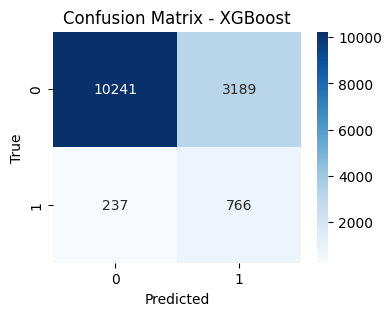

In [75]:
cm = confusion_matrix(y_valid, valid_pred)

plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - XGBoost")
plt.show()

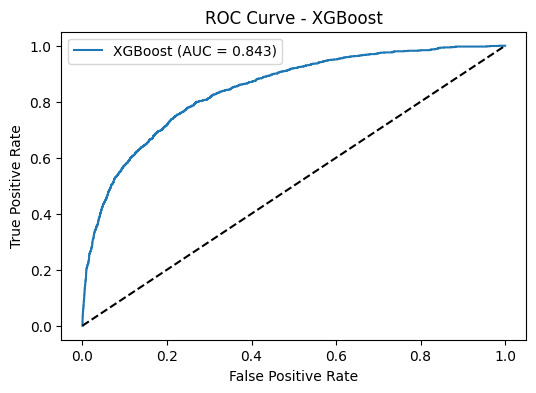

In [76]:
fpr, tpr, _ = roc_curve(y_valid, valid_proba)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"XGBoost (AUC = {roc:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")
plt.legend()
plt.show()

The results from just the best params, we have low recall for defaults - we are missing around 87% of defaulters, so we can do the same as we tried for random forest - tune threshold.
                
                Pred 0     Pred 1
True 0          13353        77
True 1           869        134



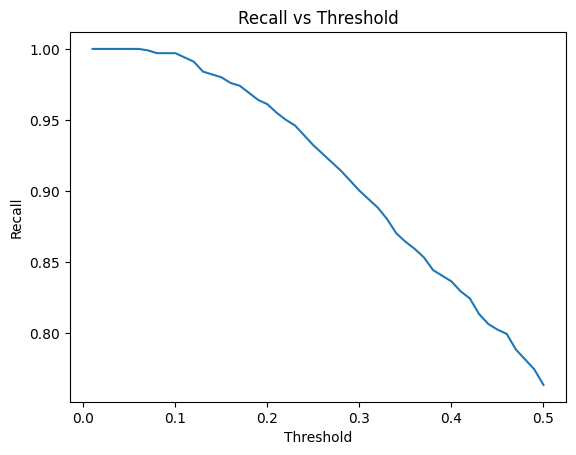

In [57]:
thresholds = np.linspace(0.01, 0.5, 50)
recalls = []

for t in thresholds:
    pred = (valid_proba >= t).astype(int)
    recalls.append(recall_score(y_valid, pred))

plt.plot(thresholds, recalls)
plt.xlabel("Threshold")
plt.ylabel("Recall")
plt.title("Recall vs Threshold")
plt.show()

In [82]:
best_model.fit(X, y)

test_proba = best_model.predict_proba(X_test_final)[:, 1] #for final submission we submit probabilities, not labels

submission = pd.DataFrame({
    "Id": test_ids,
    "Predicted": test_proba
})

submission.to_csv("../data/xgboost_submission.csv", index=False)
submission.head()

,Id,Predicted
0,1,0.750682
1,2,0.943653
2,3,0.170872
3,4,0.227626
4,5,0.870499


In [80]:
print(X.shape)
print(X_test_final.shape)
print(submission.shape)
submission.isnull().sum()

(72161, 8)
(48108, 8)
(48108, 2)


Id           0
Predicted    0
dtype: int64

In [79]:
print(submission["Predicted"].min(), submission["Predicted"].max())

0.045549247 0.97991806
